# ProofChain AI
### AI-Secured Data Integrity and Trust Verification

**IBM Z Datathon 2026 — AI Secured: Innovation Without Exposure**

## 1. Project Overview

ProofChain AI is a data integrity and verification system designed to identify suspicious changes in business datasets before they are trusted for further analysis.

Traditional data validation checks whether data follows expected formats and rules. ProofChain AI adds multiple layers of verification:

- **Cryptographic integrity:** SHA-256 hashes and an evidence chain help identify files that have changed since registration.
- **Provenance validation:** Checks whether records contain expected source and update information.
- **Machine learning:** Uses a Random Forest classifier and Isolation Forest anomaly detection to identify suspicious patterns.
- **Trust scoring:** Assigns a trust score and a verification verdict to guide human review.
- **Explainable results:** Summarizes detected concerns in understandable language.

### Demonstration objective

Compare an approved business dataset with a suspiciously modified dataset and demonstrate how ProofChain AI distinguishes between them.

**Dataset note:** The project uses Superstore sales data. The provenance fields (`Source_System`, `Last_Modified_By`, and `Last_Updated`) are simulated for demonstration purposes and are not original fields from the source dataset.

In [1]:
from pathlib import Path
import os

PROJECT_DIR = Path("/home/ibm-user/VSCODE/ProofChain_AI_GitHub")
os.chdir(PROJECT_DIR)

DATA_DIR = PROJECT_DIR / "data"

print("Project exists:", PROJECT_DIR.exists())
print("Data folder exists:", DATA_DIR.exists())
print("Master dataset exists:", (DATA_DIR / "clean_master.csv").exists())
print("Verification script exists:", (PROJECT_DIR / "verify.py").exists())

Project exists: True
Data folder exists: True
Master dataset exists: True
Verification script exists: True


In [2]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# Define the project data paths
DATA_DIR = PROJECT_DIR / "data"

master_path = DATA_DIR / "clean_master.csv"
approved_path = DATA_DIR / "demo_approved.csv"
suspicious_path = DATA_DIR / "demo_suspicious.csv"

# Load the master dataset
master_df = pd.read_csv(master_path)

print("DATASET OVERVIEW")
print("-" * 40)
print(f"Number of rows: {master_df.shape[0]:,}")
print(f"Number of columns: {master_df.shape[1]}")
print(f"Memory usage: {master_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

print("\nCOLUMN NAMES")
print(master_df.columns.tolist())

print("\nFIRST 5 RECORDS")
display(master_df.head())

DATASET OVERVIEW
----------------------------------------
Number of rows: 9,800
Number of columns: 21
Memory usage: 10.43 MB

COLUMN NAMES
['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales', 'Source_System', 'Last_Modified_By', 'Last_Updated']

FIRST 5 RECORDS


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales,Source_System,Last_Modified_By,Last_Updated
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,ERP-Finance,alice,2017-11-18
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,ERP-Finance,carol,2017-11-16
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,ERP-Finance,bob,2017-06-22
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,ERP-Finance,bob,2016-10-21
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold N Roll Cart System,22.3680,ERP-Finance,bob,2016-10-27


## 2. Data Quality Inspection

Before verifying file integrity, we inspect the master dataset for missing values, duplicate records, and invalid date sequences.

These checks provide a baseline for understanding the data. They complement ProofChain AI's cryptographic and machine-learning checks; they do not, by themselves, prove that a file is authentic.

In [3]:
# Check for missing values
print("MISSING VALUES BY COLUMN")
missing_values = master_df.isnull().sum()
display(missing_values[missing_values > 0].to_frame("Missing Count"))

if missing_values.sum() == 0:
    print("No missing values found.")

# Check for duplicate rows
print("\nDUPLICATE ROWS")
print("Exact duplicate rows:", master_df.duplicated().sum())

# Check whether order dates occur after shipping dates
master_df["Order_Date"] = pd.to_datetime(master_df["Order_Date"], errors="coerce")
master_df["Ship_Date"] = pd.to_datetime(master_df["Ship_Date"], errors="coerce")
master_df["Last_Updated"] = pd.to_datetime(master_df["Last_Updated"], errors="coerce")

invalid_shipping = (master_df["Ship_Date"] < master_df["Order_Date"]).sum()

print("\nDATE VALIDATION")
print("Rows where shipping precedes ordering:", invalid_shipping)

# Inspect sales values
print("\nSALES SUMMARY")
display(master_df["Sales"].describe().to_frame())

# Check provenance completeness
provenance_columns = [
    "Source_System",
    "Last_Modified_By",
    "Last_Updated"
]

print("\nPROVENANCE COMPLETENESS")
display(
    master_df[provenance_columns]
    .isnull()
    .sum()
    .to_frame("Missing Count")
)

MISSING VALUES BY COLUMN


,Missing Count
Postal_Code,11



DUPLICATE ROWS
Exact duplicate rows: 0

DATE VALIDATION
Rows where shipping precedes ordering: 0

SALES SUMMARY


,Sales
count,9800.000000
mean,230.769059
std,626.651875
min,0.444000
25%,17.248000
50%,54.490000
75%,210.605000
max,22638.480000



PROVENANCE COMPLETENESS


,Missing Count
Source_System,0
Last_Modified_By,0
Last_Updated,0


## 3. Cryptographic Integrity Verification

ProofChain AI uses SHA-256 hashes and an evidence chain to verify registered files. A change to a file's contents produces a different hash, allowing the system to detect that the file no longer matches its registered version.

In this demonstration, we compare an approved dataset with a suspicious dataset. The verification result combines chain membership with data-quality, provenance, and machine-learning signals.

**Important distinction:** A file that is not registered in the chain is unverified; that fact alone does not prove malicious activity.

In [4]:
import json

chain_path = DATA_DIR / "chain.json"

with open(chain_path, "r", encoding="utf-8") as file:
    chain_data = json.load(file)

print("EVIDENCE CHAIN INSPECTION")
print("-" * 40)
print("Chain file:", chain_path.name)
print("Top-level data type:", type(chain_data).__name__)

if isinstance(chain_data, dict):
    print("Top-level keys:", list(chain_data.keys()))
elif isinstance(chain_data, list):
    print("Number of chain entries:", len(chain_data))

print("\nChain file size:", f"{chain_path.stat().st_size:,} bytes")

EVIDENCE CHAIN INSPECTION
----------------------------------------
Chain file: chain.json
Top-level data type: list
Number of chain entries: 2

Chain file size: 921 bytes


## 4. Approved vs Suspicious Dataset Verification

We now evaluate two demonstration files using ProofChain AI's verification pipeline:

- **Approved dataset:** A legitimate edit that was registered in the evidence chain.
- **Suspicious dataset:** A modified file containing missing provenance information and sales changes without a corresponding update trail.

The system evaluates chain membership, detected data changes, provenance completeness, and anomaly signals to produce a trust score and verdict.

In [5]:
import subprocess
import sys

def run_verification(file_path):
    print(f"\n{'=' * 65}")
    print(f"VERIFYING: {file_path.name}")
    print("=" * 65)

    result = subprocess.run(
        [sys.executable, "verify.py", str(file_path)],
        cwd=PROJECT_DIR,
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.stderr.strip():
        print("Additional messages:")
        print(result.stderr)

    print("Process exit code:", result.returncode)

    return result.returncode

approved_exit = run_verification(approved_path)
suspicious_exit = run_verification(suspicious_path)


VERIFYING: demo_approved.csv

demo_approved.csv: TRUST 100/100 -> READY FOR REVIEW

Verdict: READY FOR REVIEW (trust 100/100). No issues were detected. Recommended first step: proceed with normal review.

saved reports/last_report.html

Process exit code: 0

VERIFYING: demo_suspicious.csv

demo_suspicious.csv: TRUST 1/100 -> REJECT - LIKELY TAMPERED
  - file hash is not in the evidence chain
  - 5.0% of Sales values changed with no update trail
  - 10.0% of rows have missing provenance
  - isolation forest flags the pattern as anomalous

Verdict: REJECT - LIKELY TAMPERED (trust 1/100). Main concerns: file hash is not in the evidence chain; 5.0% of Sales values changed with no update trail; 10.0% of rows have missing provenance; isolation forest flags the pattern as anomalous. Recommended first step: compare against the last registered version and ask the file owner who changed it.

saved reports/last_report.html

Process exit code: 0


## 5. Verification Results and Interpretation

The approved dataset received a trust score of 100/100, while the suspicious dataset received 1/100.

The suspicious file had 5% of its sales values changed without an update trail and missing provenance in 10% of its rows. Its hash was also absent from the evidence chain, and the Isolation Forest model flagged its pattern as anomalous.

These results demonstrate how combining cryptographic verification, provenance checks, and anomaly detection can help identify files that require investigation.

**Interpretation:** A rejection indicates that the file should not be trusted without further verification. It is a risk signal, not conclusive proof of malicious intent. Similarly, “READY FOR REVIEW” does not replace normal business approval procedures.

In [6]:
comparison_df = pd.DataFrame([
    {
        "Dataset": "Approved",
        "Trust Score": "100/100",
        "Verdict": "READY FOR REVIEW",
        "Hash Registered": "Yes",
        "Provenance Missing": "0%",
        "Sales Changes Without Trail": "0%"
    },
    {
        "Dataset": "Suspicious",
        "Trust Score": "1/100",
        "Verdict": "REJECT - LIKELY TAMPERED",
        "Hash Registered": "No",
        "Provenance Missing": "10%",
        "Sales Changes Without Trail": "5%"
    }
])

display(comparison_df)

,Dataset,Trust Score,Verdict,Hash Registered,Provenance Missing,Sales Changes Without Trail
0,Approved,100/100,READY FOR REVIEW,Yes,0%,0%
1,Suspicious,1/100,REJECT - LIKELY TAMPERED,No,10%,5%


In [7]:
metrics_path = PROJECT_DIR / "reports" / "metrics.txt"

print("SAVED MODEL EVALUATION")
print("-" * 40)

if metrics_path.exists():
    print(metrics_path.read_text(encoding="utf-8"))
else:
    print("Metrics file was not found.")

SAVED MODEL EVALUATION
----------------------------------------
              precision    recall  f1-score   support

       clean       0.96      1.00      0.98        25
    tampered       1.00      0.96      0.98        25

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50

Confusion matrix:
[[25  0]
 [ 1 24]]

Feature importance:
prov_missing_frac      0.216042
ship_before_order      0.118378
silent_change_frac     0.108983
updated_before_ship    0.103056
missing_rows_frac      0.101332
trail_frac             0.084795
row_ratio              0.080139
dup_ids                0.075775
sales_mean_ratio       0.065070
sales_changed_frac     0.046431
dtype: float64



## 6. Machine-Learning Model Evaluation

ProofChain AI uses a Random Forest classifier to distinguish between clean and tampered data patterns. An Isolation Forest complements it by flagging unusual patterns.

### Evaluation results

On the project's 50-example test set:

- **Accuracy:** 98%
- **Clean-class precision:** 96%
- **Clean-class recall:** 100%
- **Tampered-class precision:** 100%
- **Tampered-class recall:** 96%

The confusion matrix contains 25 correctly classified clean examples, 24 correctly classified tampered examples, and one tampered example classified as clean.

These results show promising performance on the current evaluation set. Because the test set is small and based on the project's particular data-generation setup, the scores should not be treated as a guarantee of real-world performance.

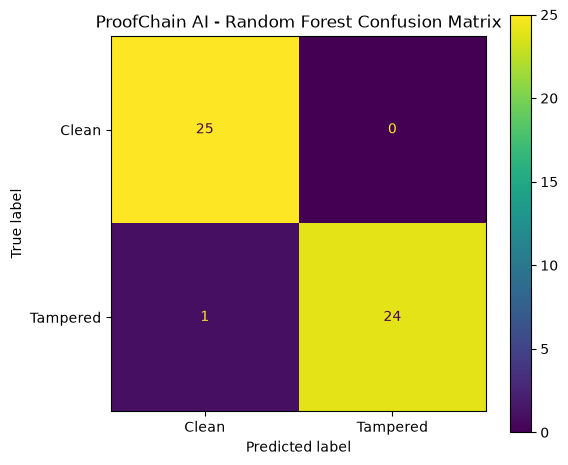

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = np.array([
    [25, 0],
    [1, 24]
])

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Clean", "Tampered"]
)

fig, ax = plt.subplots(figsize=(6, 5))
display_plot.plot(ax=ax, values_format="d")
ax.set_title("ProofChain AI - Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

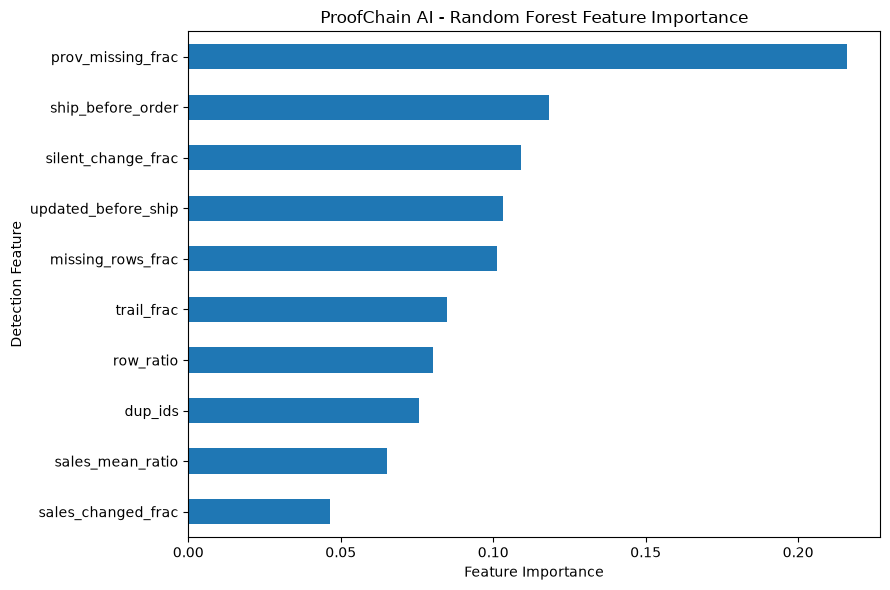

In [9]:
feature_importance = pd.Series({
    "prov_missing_frac": 0.216042,
    "ship_before_order": 0.118378,
    "silent_change_frac": 0.108983,
    "updated_before_ship": 0.103056,
    "missing_rows_frac": 0.101332,
    "trail_frac": 0.084795,
    "row_ratio": 0.080139,
    "dup_ids": 0.075775,
    "sales_mean_ratio": 0.065070,
    "sales_changed_frac": 0.046431
}).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
feature_importance.plot(kind="barh", ax=ax)
ax.set_title("ProofChain AI - Random Forest Feature Importance")
ax.set_xlabel("Feature Importance")
ax.set_ylabel("Detection Feature")
plt.tight_layout()
plt.show()

## 7. Conclusion

ProofChain AI demonstrates a layered approach to business-data integrity by combining cryptographic verification, provenance checks, and machine-learning-based anomaly detection.

In our demonstration:

- The approved dataset received a trust score of **100/100** and was marked **READY FOR REVIEW**.
- The suspicious dataset received a trust score of **1/100** and was marked **REJECT - LIKELY TAMPERED**.
- The Random Forest achieved **98% accuracy on a 50-example test set**.
- Provenance completeness was the most important feature in the saved model evaluation.

These results demonstrate how multiple verification signals can help organizations identify suspicious data changes and prioritize files for human investigation.

## 8. IBM LinuxONE Integration

The project was executed in a Python 3.12.15 environment on IBM LinuxONE (`s390x`). The data preparation, model training, evidence-chain registration, and verification scripts ran in that environment.

This demonstrates the project's execution on the IBM LinuxONE platform. It does not, by itself, establish production deployment, hardware-accelerated AI, or enterprise-scale performance.

## 9. Limitations and Future Improvements

- **Simulated provenance:** The provenance fields are added for demonstration; they are not original Superstore dataset fields.
- **Small evaluation set:** The reported 98% accuracy comes from only 50 test examples.
- **Controlled tampering:** More diverse and realistic data modifications are needed for stronger evaluation.
- **Human oversight:** Verification verdicts are risk indicators and should be reviewed before consequential business decisions.
- **Future improvements:** Evaluate on larger datasets, test more attack patterns, and strengthen key management and evidence-chain protection.

## Final Takeaway

**ProofChain AI helps make data trust measurable by combining cryptographic evidence with explainable anomaly detection.** It aims to help users identify suspicious files before relying on them for important decisions.

In [10]:
import sys
import platform

print("Python:", sys.version)
print("Architecture:", platform.machine())

Python: 3.12.15 (main, Oct  1 2026, 00:00:00) [GCC 14.3.1 20251022 (Red Hat 14.3.1-4)]
Architecture: s390x


In [11]:
import os

print("Current folder:", os.getcwd())
print("\nFiles and folders here:")
print(os.listdir("."))

Current folder: /home/ibm-user/VSCODE/ProofChain_AI_GitHub

Files and folders here:
['evaluate.py', 'prepare_data.py', '.gitignore', 'proofchain', 'app.py', 'data', 'superstore.csv', 'models', 'sample.txt', 'README.md', '.git', 'train.py', 'verify.py', '.vscode', 'requirements.txt', 'reports']


In [12]:
import os

matches = []

for root, dirs, files in os.walk(os.getcwd()):
    dirs[:] = [d for d in dirs if d not in {".git", ".venv", "venv", "__pycache__"}]
    if "verify.py" in files:
        matches.append(os.path.join(root, "verify.py"))

for path in matches:
    print(path)

/home/ibm-user/VSCODE/ProofChain_AI_GitHub/verify.py


In [13]:
import os

matches = []

for root, dirs, files in os.walk(os.getcwd()):
    dirs[:] = [d for d in dirs if d not in {".git", ".venv", "venv", "__pycache__"}]
    if "verify.py" in files:
        matches.append(os.path.join(root, "verify.py"))

for path in matches:
    print(path)

/home/ibm-user/VSCODE/ProofChain_AI_GitHub/verify.py


In [14]:
os.chdir(os.path.dirname(matches[0]))
print("Project folder:", os.getcwd())
print("Project files:", os.listdir("."))

Project folder: /home/ibm-user/VSCODE/ProofChain_AI_GitHub
Project files: ['evaluate.py', 'prepare_data.py', '.gitignore', 'proofchain', 'app.py', 'data', 'superstore.csv', 'models', 'sample.txt', 'README.md', '.git', 'train.py', 'verify.py', '.vscode', 'requirements.txt', 'reports']


In [15]:
import os
from pathlib import Path

PROJECT_DIR = Path("/home/ibm-user/VSCODE/ProofChain_AI_GitHub")
os.chdir(PROJECT_DIR)

print("Project directory:", os.getcwd())
print("\nProject files:")
for item in sorted(PROJECT_DIR.iterdir()):
    print(item.name)

Project directory: /home/ibm-user/VSCODE/ProofChain_AI_GitHub

Project files:
.git
.gitignore
.vscode
README.md
app.py
data
evaluate.py
models
prepare_data.py
proofchain
reports
requirements.txt
sample.txt
superstore.csv
train.py
verify.py


In [16]:
from pathlib import Path
import os

PROJECT_DIR = Path("/home/ibm-user/VSCODE/ProofChain_AI_GitHub")
os.chdir(PROJECT_DIR)

print("Current directory:", Path.cwd())
print("Project directory exists:", PROJECT_DIR.exists())
print("Files available:", (PROJECT_DIR / "train.py").exists(),
      (PROJECT_DIR / "verify.py").exists())

Current directory: /home/ibm-user/VSCODE/ProofChain_AI_GitHub
Project directory exists: True
Files available: True True


In [17]:
required_files = [
    "app.py",
    "prepare_data.py",
    "train.py",
    "verify.py",
    "evaluate.py",
    "requirements.txt",
]

for filename in required_files:
    print(f"{filename}: {'FOUND' if (PROJECT_DIR / filename).exists() else 'MISSING'}")

app.py: FOUND
prepare_data.py: FOUND
train.py: FOUND
verify.py: FOUND
evaluate.py: FOUND
requirements.txt: FOUND


In [18]:
for folder in ["data", "models", "proofchain", "reports"]:
    path = PROJECT_DIR / folder
    print(f"\n{folder}: {'FOUND' if path.exists() else 'MISSING'}")
    if path.exists():
        print([item.name for item in path.iterdir()])


data: FOUND
['demo_suspicious.csv', 'clean_master.csv', 'demo_master.csv', 'chain.json', '.gitkeep', 'demo_approved.csv']

models: FOUND
['proofchain_model.joblib']

proofchain: FOUND
['config.py', '__pycache__', 'data.py', '__init__.py', 'explain.py', 'features.py', 'chain.py', 'report.py', 'model.py', 'tamper.py']

reports: FOUND
['features.csv', 'last_report.html', 'metrics.txt']


In [19]:
from pathlib import Path
import os

PROJECT_DIR = Path("/home/ibm-user/VSCODE/ProofChain_AI_GitHub")
os.chdir(PROJECT_DIR)

print("Current directory:", Path.cwd())
print("\nData folder exists:", (PROJECT_DIR / "data").exists())

if (PROJECT_DIR / "data").exists():
    print("\nFiles in data folder:")
    for file in sorted((PROJECT_DIR / "data").iterdir()):
        print(file.name)

Current directory: /home/ibm-user/VSCODE/ProofChain_AI_GitHub

Data folder exists: True

Files in data folder:
.gitkeep
chain.json
clean_master.csv
demo_approved.csv
demo_master.csv
demo_suspicious.csv


In [20]:
from pathlib import Path

for name in [
    "data",
    "models",
    "reports",
    "proofchain",
    "prepare_data.py",
    "train.py",
    "verify.py",
    "evaluate.py",
]:
    path = PROJECT_DIR / name
    print(f"\n{name}: {'FOUND' if path.exists() else 'MISSING'}")

    if path.is_dir():
        print("  Contents:", sorted(item.name for item in path.iterdir()))


data: FOUND
  Contents: ['.gitkeep', 'chain.json', 'clean_master.csv', 'demo_approved.csv', 'demo_master.csv', 'demo_suspicious.csv']

models: FOUND
  Contents: ['proofchain_model.joblib']

reports: FOUND
  Contents: ['features.csv', 'last_report.html', 'metrics.txt']

proofchain: FOUND
  Contents: ['__init__.py', '__pycache__', 'chain.py', 'config.py', 'data.py', 'explain.py', 'features.py', 'model.py', 'report.py', 'tamper.py']

prepare_data.py: FOUND

train.py: FOUND

verify.py: FOUND

evaluate.py: FOUND


In [21]:
script = PROJECT_DIR / "prepare_data.py"
print(script.read_text())

"""Step 1: turn the original Superstore CSV into data/clean_master.csv (adds simulated provenance).
Usage: python prepare_data.py path/to/superstore.csv"""
import sys
import numpy as np
import pandas as pd
from proofchain.config import MASTER_CSV

if len(sys.argv) < 2:
    sys.exit("Usage: python prepare_data.py path/to/superstore.csv")

for enc in ("utf-8", "cp1252", "latin-1"):
    try:
        df = pd.read_csv(sys.argv[1], encoding=enc)
        print("read file with encoding:", enc)
        break
    except UnicodeDecodeError:
        continue
df.columns = [c.replace(" ", "_").replace("-", "_") for c in df.columns]
df["Order_Date"] = pd.to_datetime(df["Order_Date"], dayfirst=True)
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"], dayfirst=True)

# SIMULATED provenance metadata (say so in the video): Superstore has none of its own
rng = np.random.default_rng(42)
df["Source_System"] = "ERP-Finance"
df["Last_Modified_By"] = rng.choice(["alice", "bob", "carol"], len(df))
df["Last_Update

In [22]:
from pathlib import Path

search_locations = [
    Path("/home/ibm-user/VSCODE/ProofChain_AI_GitHub"),
    Path("/home/ibm-user/VSCODE/ProofChain_AI"),
    Path("/home/ibm-user/VSCODE/ProofChain_AI/proofchain_project"),
]

for folder in search_locations:
    print(f"\n--- {folder} ---")

    if not folder.exists():
        print("Folder not found")
        continue

    csv_files = list(folder.rglob("*.csv"))

    if csv_files:
        for file in csv_files:
            print(file)
    else:
        print("No CSV files found")


--- /home/ibm-user/VSCODE/ProofChain_AI_GitHub ---
/home/ibm-user/VSCODE/ProofChain_AI_GitHub/superstore.csv
/home/ibm-user/VSCODE/ProofChain_AI_GitHub/data/demo_suspicious.csv
/home/ibm-user/VSCODE/ProofChain_AI_GitHub/data/clean_master.csv
/home/ibm-user/VSCODE/ProofChain_AI_GitHub/data/demo_master.csv
/home/ibm-user/VSCODE/ProofChain_AI_GitHub/data/demo_approved.csv
/home/ibm-user/VSCODE/ProofChain_AI_GitHub/reports/features.csv

--- /home/ibm-user/VSCODE/ProofChain_AI ---
Folder not found

--- /home/ibm-user/VSCODE/ProofChain_AI/proofchain_project ---
Folder not found


In [23]:
%run /home/ibm-user/VSCODE/ProofChain_AI_GitHub/prepare_data.py /home/ibm-user/VSCODE/ProofChain_AI_GitHub/superstore.csv

read file with encoding: cp1252
saved /home/ibm-user/VSCODE/ProofChain_AI_GitHub/data/clean_master.csv (9800, 21)
ship before order: 0


In [24]:
for filename in ["train.py", "proofchain/config.py", "proofchain/chain.py"]:
    path = PROJECT_DIR / filename
    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)
    print(path.read_text())


train.py
"""Step 2: build 200 labelled versions, train the models, register the master, create demo files.
Usage: python train.py"""
import io
from proofchain.chain import EvidenceChain
from proofchain.config import DATA_DIR, MASTER_CSV, REPORT_DIR
from proofchain.data import df_bytes, load_csv
from proofchain.model import build_dataset, save_bundle, train
from proofchain.tamper import change_values, drop_provenance, legit_edit

master = load_csv(MASTER_CSV)
print("master:", master.shape)

feat = build_dataset(master)
feat.to_csv(REPORT_DIR / "features.csv", index=False)
bundle, report, cm, importances = train(feat)
save_bundle(bundle)
text = f"{report}\nConfusion matrix:\n{cm}\n\nFeature importance:\n{importances}\n"
(REPORT_DIR / "metrics.txt").write_text(text)
print(text)

# Fresh evidence chain: register the original master file (exact bytes)
chain = EvidenceChain()
chain.blocks = []
chain.register(MASTER_CSV.read_bytes(), note="original master", name=MASTER_CSV.name)

# Demo file

In [25]:
%run train.py

master: (9800, 21)
              precision    recall  f1-score   support

       clean       0.96      1.00      0.98        25
    tampered       1.00      0.96      0.98        25

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50

Confusion matrix:
[[25  0]
 [ 1 24]]

Feature importance:
prov_missing_frac      0.216042
ship_before_order      0.118378
silent_change_frac     0.108983
updated_before_ship    0.103056
missing_rows_frac      0.101332
trail_frac             0.084795
row_ratio              0.080139
dup_ids                0.075775
sales_mean_ratio       0.065070
sales_changed_frac     0.046431
dtype: float64

chain blocks: 2 | intact: True
Demo files in /home/ibm-user/VSCODE/ProofChain_AI_GitHub/data


In [26]:
%run verify.py data/demo_suspicious.csv


demo_suspicious.csv: TRUST 1/100 -> REJECT - LIKELY TAMPERED
  - file hash is not in the evidence chain
  - 5.0% of Sales values changed with no update trail
  - 10.0% of rows have missing provenance
  - isolation forest flags the pattern as anomalous

Verdict: REJECT - LIKELY TAMPERED (trust 1/100). Main concerns: file hash is not in the evidence chain; 5.0% of Sales values changed with no update trail; 10.0% of rows have missing provenance; isolation forest flags the pattern as anomalous. Recommended first step: compare against the last registered version and ask the file owner who changed it.

saved reports/last_report.html


In [27]:
from pathlib import Path

for folder in ["data", "models", "reports"]:
    path = PROJECT_DIR / folder
    print(f"\n{folder}/")
    for item in sorted(path.iterdir()):
        if item.is_file():
            print(f"  {item.name} — {item.stat().st_size:,} bytes")


data/
  .gitkeep — 0 bytes
  chain.json — 921 bytes
  clean_master.csv — 2,423,759 bytes
  demo_approved.csv — 2,423,639 bytes
  demo_master.csv — 2,423,759 bytes
  demo_suspicious.csv — 2,412,865 bytes

models/
  proofchain_model.joblib — 955,886 bytes

reports/
  features.csv — 17,714 bytes
  last_report.html — 1,148 bytes
  metrics.txt — 720 bytes


In [28]:
from pathlib import Path
import os

PROJECT_DIR = Path("/home/ibm-user/VSCODE/ProofChain_AI_GitHub")
os.chdir(PROJECT_DIR)

print("Project directory:", Path.cwd())
print("verify.py exists:", (PROJECT_DIR / "verify.py").exists())
print("train.py exists:", (PROJECT_DIR / "train.py").exists())

Project directory: /home/ibm-user/VSCODE/ProofChain_AI_GitHub
verify.py exists: True
train.py exists: True


In [29]:
%run /home/ibm-user/VSCODE/ProofChain_AI_GitHub/verify.py /home/ibm-user/VSCODE/ProofChain_AI_GitHub/data/demo_approved.csv


demo_approved.csv: TRUST 100/100 -> READY FOR REVIEW

Verdict: READY FOR REVIEW (trust 100/100). No issues were detected. Recommended first step: proceed with normal review.

saved reports/last_report.html


In [30]:
%run /home/ibm-user/VSCODE/ProofChain_AI_GitHub/verify.py /home/ibm-user/VSCODE/ProofChain_AI_GitHub/data/demo_suspicious.csv


demo_suspicious.csv: TRUST 1/100 -> REJECT - LIKELY TAMPERED
  - file hash is not in the evidence chain
  - 5.0% of Sales values changed with no update trail
  - 10.0% of rows have missing provenance
  - isolation forest flags the pattern as anomalous

Verdict: REJECT - LIKELY TAMPERED (trust 1/100). Main concerns: file hash is not in the evidence chain; 5.0% of Sales values changed with no update trail; 10.0% of rows have missing provenance; isolation forest flags the pattern as anomalous. Recommended first step: compare against the last registered version and ask the file owner who changed it.

saved reports/last_report.html
